# Machine Learning: Exercise 1

## Classification with k-Nearest Neighbors (kNN)

### Task 1
Load the Iris dataset and split it into training and testing sets with a ratio of 70% training and 30% testing.

In [ ]:
%pip install scikit-learn==1.4.2
%pip install matplotlib==3.8.4
%pip install numpy==1.26.4

In [23]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)
    
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (105, 4)
y_train shape: (105,)
X_test shape: (45, 4)
y_test shape: (45,)


### Task 2
Standardize the feature values using StandardScaler.

In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Task 3
Train a kNN classifier with k = 5 using the training data.

In [25]:
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train_scaled, y_train)

KNeighborsClassifier()

### Task 4
Evaluate the model on the test set by:
•	Computing accuracy
•	Displaying the confusion matrix
•	Printing the classification report

Accuracy: 1.0


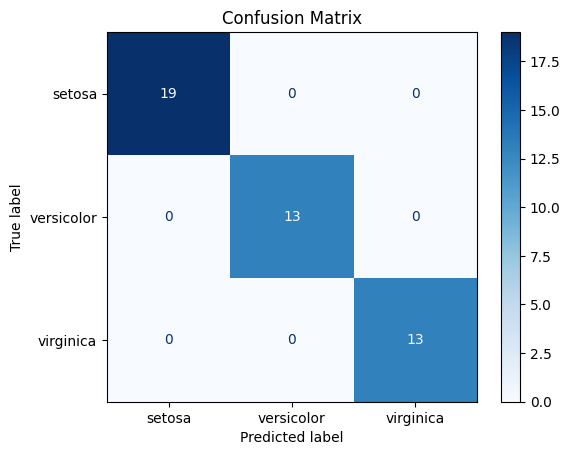

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



In [26]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)
disp.plot(cmap=plt.cm.Blues) 
plt.title("Confusion Matrix")
plt.show()


print("Classification Report:")
report = classification_report(y_test, y_pred)
print(report)

### Task 5
Apply PCA to reduce the test data to 2 dimensions and visualize:

- Test samples colored by their predicted class
- A clear legend indicating each class

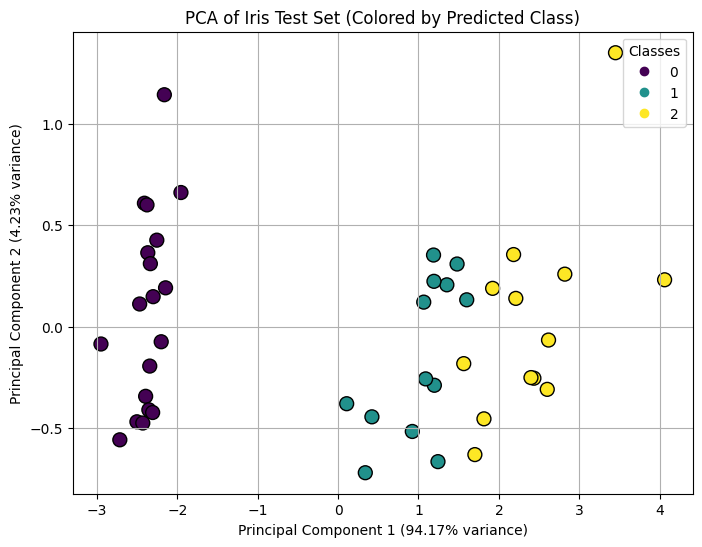

In [27]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# PCA to reduce dimensionality to 2 for visualization
pca = PCA(n_components=2) # Selecting top 2 principal components
principal_components = pca.fit_transform(X_test)
explained_variance_ratio = pca.explained_variance_ratio_


# Plot PCA: Test samples colored by their predicted class
plt.figure(figsize=(8, 6))
scatter = plt.scatter(principal_components[:, 0], principal_components[:, 1], c=y_pred, cmap='viridis', edgecolor='k', s=100)
plt.title('PCA of Iris Test Set (Colored by Predicted Class)')
plt.xlabel(f'Principal Component 1 ({explained_variance_ratio[0]:.2%} variance)')
plt.ylabel(f'Principal Component 2 ({explained_variance_ratio[1]:.2%} variance)')
plt.legend(*scatter.legend_elements(), title="Classes")
plt.grid()
plt.show()

## Regression

### Task 6
Generate a simple 1-dimensional synthetic dataset for regression.

In [73]:
import numpy as np

# Create synthetic regression dataset (1 feature - 1 target)
X_train = np.random.rand(100, 1).reshape(-1, 1) * 10  # 100 samples, 1 feature
y_train = 2.5 * X_train.flatten() + np.random.randn(100) * 5  # Linear relation with some noise
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (100, 1)
y_train shape: (100,)


### Task 7
Train a regression model (Linear Regression or kNN Regression).

In [74]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

### Task 8
Predict the output values for 5 newly generated data points.

In [75]:
# Predict the first 20 newly genarated test samples
X_test = np.random.rand(20, 1).reshape(-1, 1) * 10  
y_test = 2.5 * X_test.flatten() + np.random.randn(20) * 5

y_pred = model.predict(X_test)
print("Predictions for the first 5 test samples:", y_pred[:5])

Predictions for the first 5 test samples: [13.38295769 13.39453878  4.31555104 14.51543849  6.37590607]


### Task 9
Plot:
- Training data points
- Regression line
- Predicted points for the new data

Explain the role of reshape(-1, 1) in preparing the input data.
- `reshape(-1, 1)` is used to convert a 1D array into a 2D array with one column. This is necessary because many machine learning algorithms expect the input data to be in a 2D format (n_samples, n_features). By using reshape(-1, 1), we ensure that our single feature data is correctly formatted for training the model.

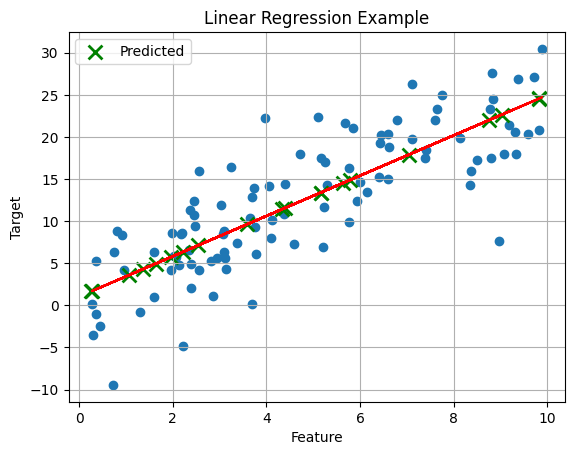

In [76]:
plt.scatter(X_train, y_train)
plt.plot(X_train, model.predict(X_train), color='red')  # Regression line
plt.xlabel("Feature")
plt.ylabel("Target")
plt.title("Linear Regression Example")
# Plot predicted points for the new data
plt.scatter(X_test, y_pred, color='green', marker='x', s=100, linewidths=2, label='Predicted')
plt.legend()
plt.grid()
plt.show()